### what is LLM
Large Language Model (LLM) là một mạng neural sâu (deep neural network) được thiết kế để hiểu, tạo ra và phản hồi văn bản giống ngôn ngữ con người.
Tác giả nhấn mạnh chữ Large có hai ý nghĩa:
- Model size: Mô hình có rất nhiều parameters (tham số), có thể lên đến hàng chục hoặc hàng trăm tỷ.
- Training dataset: Mô hình được huấn luyện trên lượng dữ liệu văn bản khổng lồ.
Các parameters chính là những trọng số có thể điều chỉnh trong quá trình huấn luyện.
LLM có khả năng thực hiện nhiều nhiệm vụ như text generation, translation, summarization và classification.  
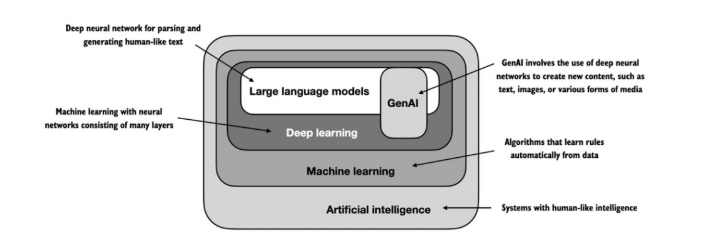 

### Next-token prediction — Dự đoán token tiếp theo  
nhiệm vụ pretraining cốt lõi của GPT là next-word prediction. Khi triển khai thực tế với tokenizer, model dự đoán token tiếp theo, mà token không nhất thiết là một từ hoàn chỉnh.  

Self-supervised learning: Không cần con người gán nhãn thủ công cho từng ví dụ. Phần tiếp theo của văn bản được dùng làm nhãn huấn luyện.
Autoregressive model: Model sử dụng chuỗi token đã có, bao gồm các token vừa sinh ra, để dự đoán token tiếp theo.
Ví dụ với chuỗi token ["I", "love", "machine", "learning"]: 

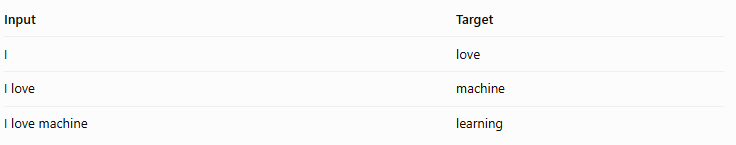  

Mô hình học dự đoán target từ input. Trong quá trình huấn luyện, các dự đoán được so sánh với token thực tế để tối ưu trọng số.
Điểm cần nhớ: GPT không tạo toàn bộ câu trong một lần dự đoán. Nó sinh từng token liên tiếp dựa trên ngữ cảnh trước đó. 

### 3. Text preprocessing — Tiền xử lý văn bản
Theo sách, LLM không thể trực tiếp xử lý văn bản thô bằng các phép toán của neural network. Vì vậy, dữ liệu văn bản cần được chuẩn bị trước khi đưa vào model.  

### Tokenization — Tách văn bản thành token
Chapter 2 — Sections 2.2, 2.5
Tokenization là quá trình chia văn bản thành các đơn vị nhỏ hơn gọi là tokens.
- có 2 cái thứ nhất là Simple tokenization: chia theo các loại dấu câu
- Byte Pair Encoding (BPE)  Biểu diễn văn bản bằng token ở mức từ, từ con hoặc đơn vị nhỏ hơn
- BPE xây dựng vocabulary bằng cách lặp lại việc gộp các cặp đơn vị xuất hiện thường xuyên, từ các đơn vị nhỏ thành các subword lớn hơn.
Ưu điểm quan trọng là có thể xử lý từ không xuất hiện nguyên vẹn trong vocabulary bằng cách chia thành những phần nhỏ hơn.
 
 Cần nhớ: Một token có thể là một từ, một phần của từ hoặc ký hiệu. Không được mặc định rằng một token luôn bằng một từ.

### Token IDs — Mã định danh của token
Sau khi tách văn bản thành tokens, mỗi token được ánh xạ đến một số nguyên duy nhất trong vocabulary.
ví dụ
[15496, 11, 466, 345, 588, 8887, 30]
Hello, do you like tea?

Sách giới thiệu hai phương thức:
- encode(): Text → Tokens → Token IDs. -> BERT
- decode(): Token IDs → Tokens → Text. -> GPT (Generative Pre-trained Transformer)
Token ID chỉ là mã định danh, không phải giá trị biểu diễn ngữ nghĩa của từ. Việc tạo biểu diễn số liên tục sẽ do embedding layer đảm nhiệm.

### Context window — Cửa sổ ngữ cảnh
- Trong phần này, sách sử dụng các thuật ngữ context_size, context_length và max_length để mô tả số token trong một đoạn đầu vào dùng cho huấn luyện.   
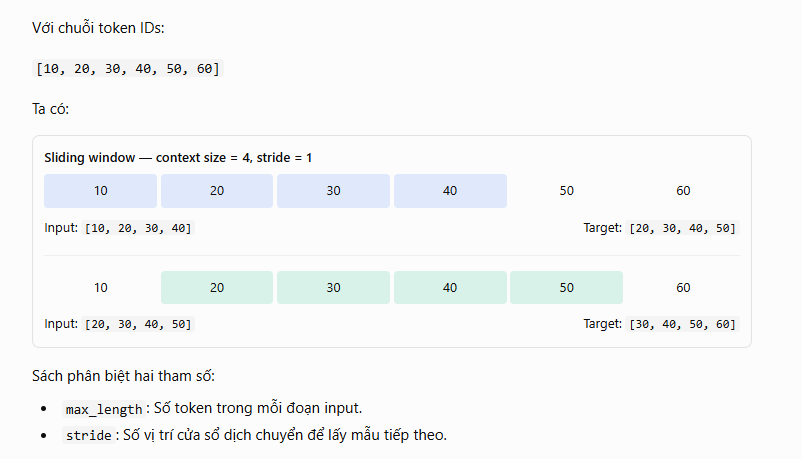  


Ví dụ max_length=4, stride=4 sẽ tạo các đoạn không chồng lấn nhau.  
Điểm cần nhớ: Context length quyết định độ dài chuỗi input trong ví dụ huấn luyện. Sliding window giúp tạo nhiều cặp input-target từ cùng một văn bản.

### Token embeddings — Biểu diễn token thành vector 

- Theo sách, embedding là phép ánh xạ các đối tượng rời rạc, như token, vào không gian vector liên tục để neural network có thể xử lý.  
- 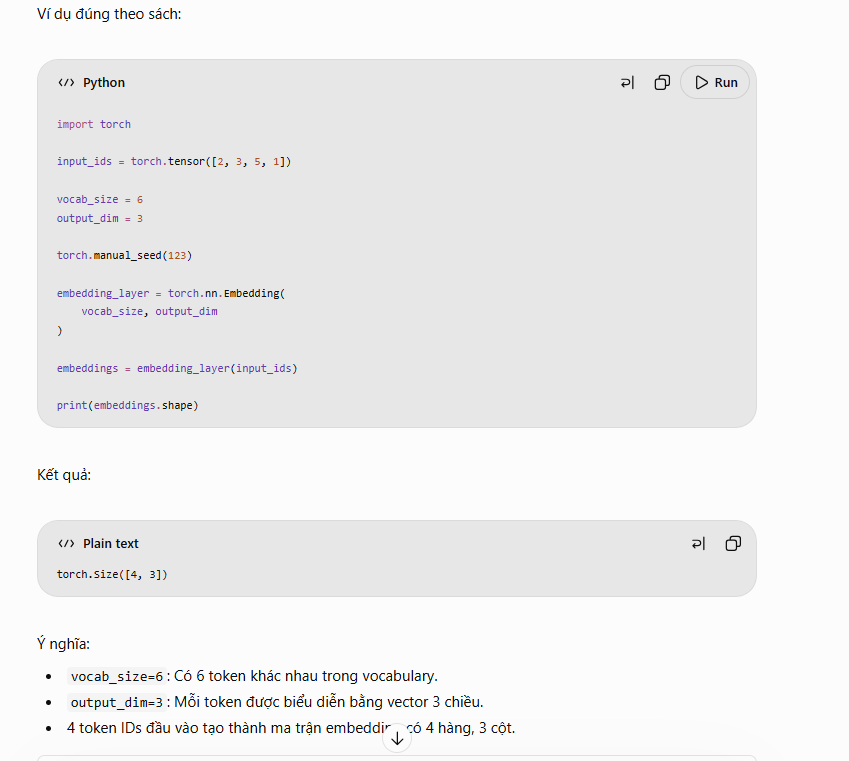  
- Ý nghĩa:
- vocab_size=6: Có 6 token khác nhau trong vocabulary.
- output_dim=3: Mỗi token được biểu diễn bằng vector 3 chiều.
- 4 token IDs đầu vào tạo thành ma trận embedding có 4 hàng, 3 cột.
  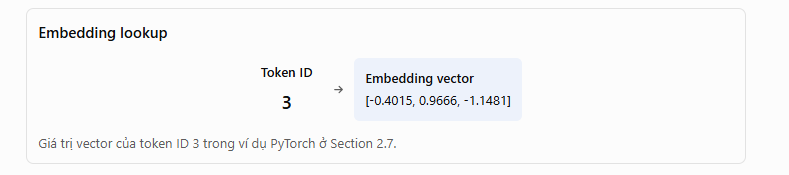
**Sách nhấn mạnh embedding layer thực chất thực hiện một lookup operation: lấy hàng tương ứng với token ID từ ma trận trọng số embedding.
Các trọng số này ban đầu được khởi tạo ngẫu nhiên và được tối ưu trong quá trình huấn luyện LLM.
Đây cũng là điểm khác biệt với việc sử dụng một mô hình Word2Vec đã huấn luyện sẵn: embedding của LLM được học cùng với chính LLM đó**  

### Positional embeddings — Biểu diễn vị trí token
Vấn đề được tác giả đặt ra là: Token embedding không tự chứa thông tin về vị trí của token trong chuỗi.
Cùng một token ID sẽ cho cùng một embedding vector dù xuất hiện ở vị trí thứ nhất hay thứ ba.  
Trong khi đó, thứ tự token rất quan trọng để hiểu ngôn ngữ.  
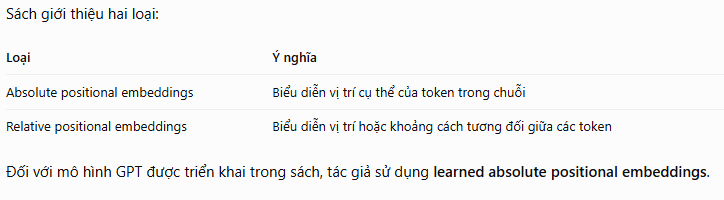  
Công thức ý tưởng:
$$
\text{Input Embedding} =
\text{Token Embedding} +
\text{Positional Embedding}
$$  

Điểm cần nhớ: Token embeddings biểu diễn token, còn positional embeddings bổ sung thông tin về vị trí để model xử lý thứ tự trong chuỗi.

## NLP

NLP Fundamentals — 11 chủ đề cần học
Dựa trên danh sách Focus bạn gửi, mình sẽ giải thích từng khái niệm theo hướng học Machine Learning và NLP, đồng thời phân biệt rõ nội dung nào nằm trong Chapter 1–2 của sách Build a Large Language Model (From Scratch) của Sebastian Raschka.
Lưu ý: Chapter 1–2 tập trung vào LLM, tokenization, BPE và embeddings. Các chủ đề như Bag-of-Words, TF-IDF, CountVectorizer, text classification và error analysis không được giảng dạy chi tiết trong hai chapter này. Mình sẽ giải thích chúng bằng kiến thức NLP truyền thống, không gán nhầm cho tác giả.
1. Classic NLP vs LLM-based NLP
NLP (Natural Language Processing) là lĩnh vực giúp máy tính xử lý và làm việc với ngôn ngữ con người.
Hai hướng tiếp cận phổ biến:  

| Tiêu chí | Classic NLP | LLM-based NLP |
| --- | --- | --- |
| **Biểu diễn văn bản** | BoW, TF-IDF, N-grams | Token embeddings, contextual representations |
| **Mô hình** | Naive Bayes, Logistic Regression, SVM | Transformer-based LLMs |
| **Huấn luyện** | Thường huấn luyện riêng cho từng tác vụ | Pretraining, sau đó prompting hoặc fine-tuning |
| **Hiểu ngữ cảnh** | Hạn chế với các đặc trưng BoW/TF-IDF | Mạnh hơn nhờ biểu diễn theo ngữ cảnh |
| **Tài nguyên** | Thường ít hơn | Thường cần nhiều tài nguyên hơn |
| **Ứng dụng** | Spam detection, sentiment classification | Chatbot, summarization, question answering |  

Ví dụ: Phân loại một email là spam hay không.
- Classic NLP: Text → TF-IDF → Logistic Regression → Spam/Not Spam
- LLM-based NLP: Text → Tokenizer → LLM → Spam/Not Spam  
  Cần nhớ: Classic NLP vẫn rất hữu ích, đặc biệt khi dữ liệu có nhãn không quá lớn, cần mô hình nhẹ, nhanh và dễ giải thích.

### Text preprocessing — Tiền xử lý văn bản  

Dưới đây là phần định dạng bảng cho các kỹ thuật tiền xử lý văn bản:

| Kỹ thuật | Ví dụ |
| --- | --- |
| **Lowercasing** | Hello $\rightarrow$ hello |
| **Remove punctuation** | Hello! $\rightarrow$ Hello |
| **Remove stopwords** | Bỏ các từ chức năng ít mang thông tin trong một số tác vụ |
| **Tokenization** | I love AI $\rightarrow$ `["I", "love", "AI"]` |
| **Stemming** | playing $\rightarrow$ play |
| **Lemmatization** | better $\rightarrow$ good (theo ngữ cảnh và bộ từ điển) |  

**Không phải mọi tác vụ đều cần thực hiện tất cả các bước. Với LLM, việc tự ý xóa dấu câu, đổi chữ hoa thành chữ thường hoặc xóa stopwords có thể làm mất thông tin quan trọng.**

### Tokenization — Tách văn bản thành token  
- Có ba cách thường gặp:
  - Word-level: Tách theo từ.
  - Character-level: Tách theo ký tự.
  - Subword-level: Tách theo các đơn vị nhỏ hơn từ, chẳng hạn BPE. 
  
### N-grams — Chuỗi N token liên tiếp 
- N-gram là một chuỗi gồm N token liên tiếp trong văn bản.
  - như Unigram N = 1, BigramN = 2, Trigram N = 3 
    - Trong scikit-learn, tham số ngram_range=(1, 2) có nghĩa là sử dụng cả unigram và bigram.

### Bag-of-Words
- là phương pháp biểu diễn văn bản bằng số lần xuất hiện của từ, bỏ qua thứ tự các từ trong câu.  
- Ví dụ:
  - Document 1: "I love AI"
  - Document 2: "I love Python"
  - Document 3: "AI loves Python"
  
  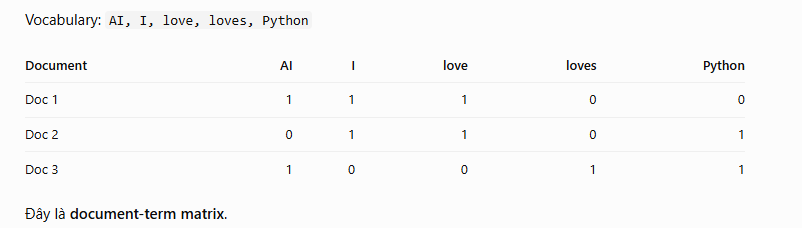  

**Nhược điểm quan trọng của BoW là không giữ được thứ tự từ và không tự biểu diễn được ngữ nghĩa.
Ví dụ hai câu "dog bites man" và "man bites dog" có cùng vector unigram BoW mặc dù ý nghĩa khác nhau.**  

### CountVectorizer
- CountVectorizer là công cụ của scikit-learn giúp tự động chuyển tập văn bản thành ma trận số đếm token.
Nó thực hiện các công việc như tokenization theo cấu hình, xây dựng vocabulary và đếm số lần xuất hiện của token hoặc N-gram.
  - BoW: Là phương pháp (ý tưởng) biểu diễn văn bản bằng cách đếm số lần xuất hiện của các từ, bỏ qua thứ tự từ.
  - CountVectorizer: Là class trong sklearn dùng để triển khai BoW.
- **CountVectorizer nó chỉ chấp nhận những từ ít nhất 2 kí tự như I là ko được vì chỉ có 1**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

docs = [
    "I love AI",
    "I love Python",
    "AI loves Python"
]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(docs)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['ai' 'love' 'loves' 'python']
[[1 1 0 0]
 [0 1 0 1]
 [1 0 1 1]]


### TF-IDF — Term Frequency–Inverse Document Frequency
- TF-IDF là phương pháp gán trọng số cho từ dựa trên mức độ xuất hiện trong một tài liệu và mức độ phổ biến của từ đó trong toàn bộ tập tài liệu.
- gồm 2 thành phần
  - TF đo mức độ xuất hiện của 1 từ trong doc
  - IDF giảm trọng số của những từ xuất hiện nhiều trong doc
    -  $$\text{TF-IDF}(t,d)=\text{TF}(t,d)\times\text{IDF}(t)$$
 -  **Cần nhớ: TF-IDF cao không đồng nghĩa từ đó chắc chắn là keyword quan trọng nhất về mặt ngữ nghĩa. Nó chỉ cho biết mức độ nổi bật thống kê của từ trong tài liệu so với corpus.**  
  
### Sparse vectors vs Dense embeddings (thưa vs dày)
- Đây là hai cách biểu diễn văn bản thành vector, nhưng bản chất khác nhau.
  - 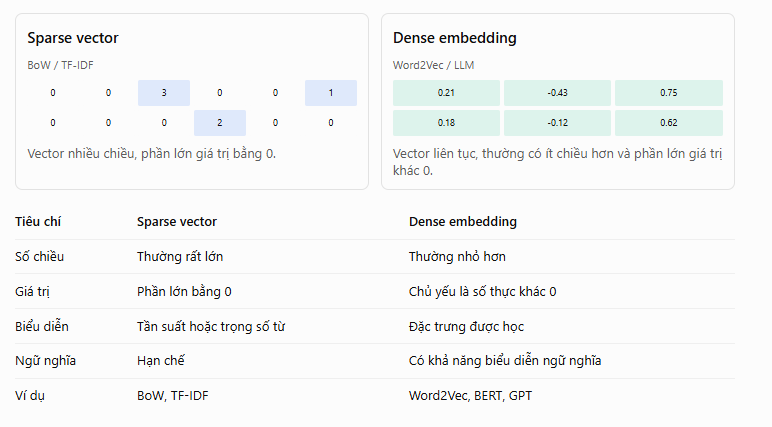

### Keyword search vs Semantic search 
- Keyword search  
    <pre>
    Tìm tài liệu dựa trên sự xuất hiện của từ hoặc cụm từ trong truy vấn. Có thể dùng TF-IDF, BM25 hoặc các thuật toán tìm kiếm từ khóa khác.
    Ví dụ truy vấn: "machine learning"
    Tài liệu chứa chính xác cụm từ này thường dễ được tìm thấy.
    </pre>
- Semantic search   
    <pre>
    Tìm tài liệu dựa trên sự tương đồng về ngữ nghĩa, thường bằng cách chuyển truy vấn và tài liệu thành dense embeddings.
    Ví dụ truy vấn: "How do computers learn from data?"
    Hệ thống có thể tìm được tài liệu về "machine learning" ngay cả khi không trùng từ khóa.
    </pre>
    

### Error analysis for text models
- Error analysis là quá trình phân tích những dự đoán sai để tìm nguyên nhân và đề xuất cách cải thiện mô hình.  
- 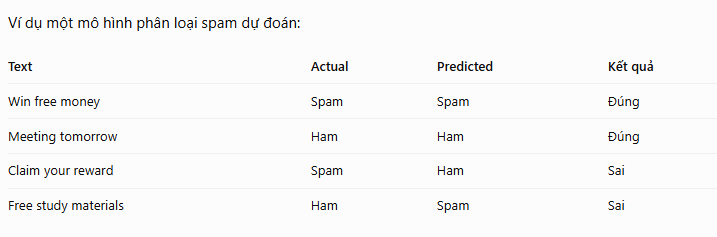  
- Quy trình error analysis:
1. Thu thập các mẫu dự đoán sai từ tập validation hoặc test.
2. Phân nhóm lỗi: false positive, false negative, lỗi dữ liệu, lỗi nhãn, lỗi preprocessing.
3. Đặt giả thuyết về nguyên nhân.
4. Thiết kế experiment thay đổi một yếu tố chính.
5. Đánh giá lại trên cùng một tập kiểm thử để so sánh công bằng.
Ví dụ cải thiện: Nếu unigram TF-IDF không phân biệt tốt các cụm như "free money" và "free materials", có thể thử ngram_range=(1, 2) rồi so sánh Precision, Recall và F1.